In [1]:
import pandas as pd
from google.colab import files
archivo = files.upload()
df = pd.read_csv("moodmusic_dataset.csv")
print(df.head())

Saving moodmusic_dataset.csv to moodmusic_dataset.csv
   id          cancion               artista             genero estado_animo  \
0   1  Part-Time Lover         Stevie Wonder         Funk / R&B      Alegría   
1   2      El Merengue         Manuel Turizo  Urbano / Merengue      Energía   
2   3          Rabiosa               Shakira       Pop / Urbano      Energía   
3   4         El Doble  Abraham Mateo; Danna                Pop      Alegría   
4   5               22                  TINI                Pop      Alegría   

   energia_0_1  valence_0_1  tempo_bpm  \
0          NaN          NaN        NaN   
1          NaN          NaN        NaN   
2          NaN          NaN        NaN   
3          NaN          NaN        NaN   
4          NaN          NaN        NaN   

                                       observaciones  
0  Clasificación inicial por su ritmo bailable y ...  
1  Clasificación inicial por su ritmo bailable; v...  
2  Clasificación inicial por su ritmo intenso y

In [2]:
# Revisar las dimensiones del dataset
print("Número de canciones y columnas:", df.shape)

# Mostrar los nombres de las columnas
print("\nColumnas del dataset:")
print(df.columns.tolist())

# Mostrar los primeros 10 registros
print("\nPrimeras 10 canciones:")
display(df.head(10))

# Información general
print("\nInformación del dataset:")
df.info()

Número de canciones y columnas: (40, 9)

Columnas del dataset:
['id', 'cancion', 'artista', 'genero', 'estado_animo', 'energia_0_1', 'valence_0_1', 'tempo_bpm', 'observaciones']

Primeras 10 canciones:


,id,cancion,artista,genero,estado_animo,energia_0_1,valence_0_1,tempo_bpm,observaciones
0,1,Part-Time Lover,Stevie Wonder,Funk / R&B,Alegría,NaN,NaN,NaN,Clasificación inicial por su ritmo bailable y ...
1,2,El Merengue,Manuel Turizo,Urbano / Merengue,Energía,NaN,NaN,NaN,Clasificación inicial por su ritmo bailable; v...
2,3,Rabiosa,Shakira,Pop / Urbano,Energía,NaN,NaN,NaN,Clasificación inicial por su ritmo intenso y b...
3,4,El Doble,Abraham Mateo; Danna,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
4,5,22,TINI,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial por su tono juvenil y an...
5,6,Universidad,TINI,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
6,7,On the Floor,Jennifer Lopez; Pitbull,Dance-pop,Energía,NaN,NaN,NaN,Clasificación inicial por su orientación baila...
7,8,#Natural,Paty Cantú; Juhn,Pop / Urbano,Tranquilidad,NaN,NaN,NaN,Clasificación provisional; confirmar si el equ...
8,9,Superestrella,Aitana,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
9,10,No Volverás,Diego Verdaguer,Balada romántica,Melancolía,NaN,NaN,NaN,Clasificación inicial por su temática de ruptu...



Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             40 non-null     int64  
 1   cancion        40 non-null     object 
 2   artista        40 non-null     object 
 3   genero         40 non-null     object 
 4   estado_animo   40 non-null     object 
 5   energia_0_1    0 non-null      float64
 6   valence_0_1    0 non-null      float64
 7   tempo_bpm      0 non-null      float64
 8   observaciones  40 non-null     object 
dtypes: float64(3), int64(1), object(5)
memory usage: 2.9+ KB


In [3]:
# 1. Revisar valores faltantes
print("VALORES FALTANTES")
print(df.isnull().sum())

# 2. Revisar registros duplicados
print("\nREGISTROS DUPLICADOS")
print("Total:", df.duplicated().sum())

# 3. Revisar canciones repetidas
print("\nCANCIONES Y ARTISTAS REPETIDOS")
print(df.duplicated(subset=["cancion", "artista"]).sum())

# 4. Revisar estadísticas generales
print("\nRESUMEN DEL DATASET")
display(df.describe(include="all"))

VALORES FALTANTES
id                0
cancion           0
artista           0
genero            0
estado_animo      0
energia_0_1      40
valence_0_1      40
tempo_bpm        40
observaciones     0
dtype: int64

REGISTROS DUPLICADOS
Total: 0

CANCIONES Y ARTISTAS REPETIDOS
0

RESUMEN DEL DATASET


,id,cancion,artista,genero,estado_animo,energia_0_1,valence_0_1,tempo_bpm,observaciones
count,40.000000,40,40,40,40,0.0,0.0,0.0,40
unique,NaN,40,35,23,4,NaN,NaN,NaN,26
top,NaN,Part-Time Lover,bbyale,Pop,Melancolía,NaN,NaN,NaN,Clasificación inicial por su temática sentimen...
freq,NaN,1,3,5,18,NaN,NaN,NaN,4
mean,20.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,11.690452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,10.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,20.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,30.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Crear una copia del dataset original
df_limpio = df.copy()

# Eliminar registros completamente duplicados
df_limpio = df_limpio.drop_duplicates()

# Eliminar canciones repetidas del mismo artista
df_limpio = df_limpio.drop_duplicates(
    subset=["cancion", "artista"]
)

# Revisar valores faltantes
print("Valores faltantes después de la revisión:")
print(df_limpio.isnull().sum())

# Revisar dimensiones finales
print("\nDimensiones del dataset limpio:")
print(df_limpio.shape)

# Mostrar los datos
display(df_limpio.head(10))

Valores faltantes después de la revisión:
id                0
cancion           0
artista           0
genero            0
estado_animo      0
energia_0_1      40
valence_0_1      40
tempo_bpm        40
observaciones     0
dtype: int64

Dimensiones del dataset limpio:
(40, 9)


,id,cancion,artista,genero,estado_animo,energia_0_1,valence_0_1,tempo_bpm,observaciones
0,1,Part-Time Lover,Stevie Wonder,Funk / R&B,Alegría,NaN,NaN,NaN,Clasificación inicial por su ritmo bailable y ...
1,2,El Merengue,Manuel Turizo,Urbano / Merengue,Energía,NaN,NaN,NaN,Clasificación inicial por su ritmo bailable; v...
2,3,Rabiosa,Shakira,Pop / Urbano,Energía,NaN,NaN,NaN,Clasificación inicial por su ritmo intenso y b...
3,4,El Doble,Abraham Mateo; Danna,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
4,5,22,TINI,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial por su tono juvenil y an...
5,6,Universidad,TINI,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
6,7,On the Floor,Jennifer Lopez; Pitbull,Dance-pop,Energía,NaN,NaN,NaN,Clasificación inicial por su orientación baila...
7,8,#Natural,Paty Cantú; Juhn,Pop / Urbano,Tranquilidad,NaN,NaN,NaN,Clasificación provisional; confirmar si el equ...
8,9,Superestrella,Aitana,Pop,Alegría,NaN,NaN,NaN,Clasificación inicial; validar con el equipo.
9,10,No Volverás,Diego Verdaguer,Balada romántica,Melancolía,NaN,NaN,NaN,Clasificación inicial por su temática de ruptu...


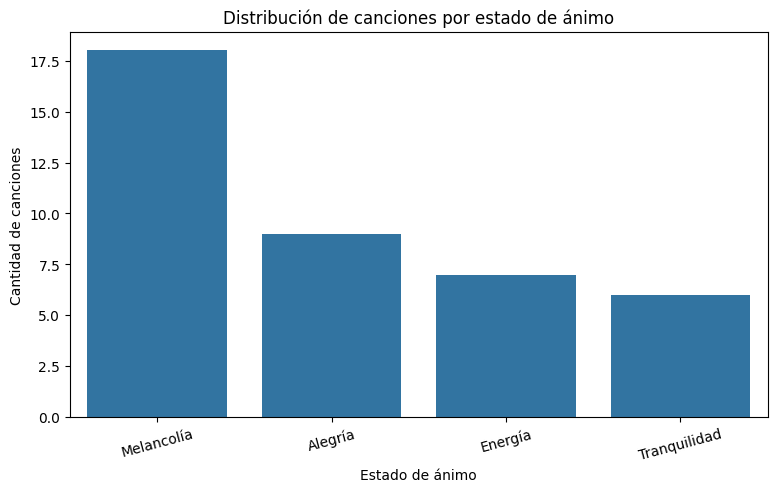

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Contar canciones por estado de ánimo
conteo = df_limpio["estado_animo"].value_counts()

# Crear gráfica
plt.figure(figsize=(9,5))
sns.barplot(x=conteo.index, y=conteo.values)

plt.title("Distribución de canciones por estado de ánimo")
plt.xlabel("Estado de ánimo")
plt.ylabel("Cantidad de canciones")
plt.xticks(rotation=15)

plt.show()

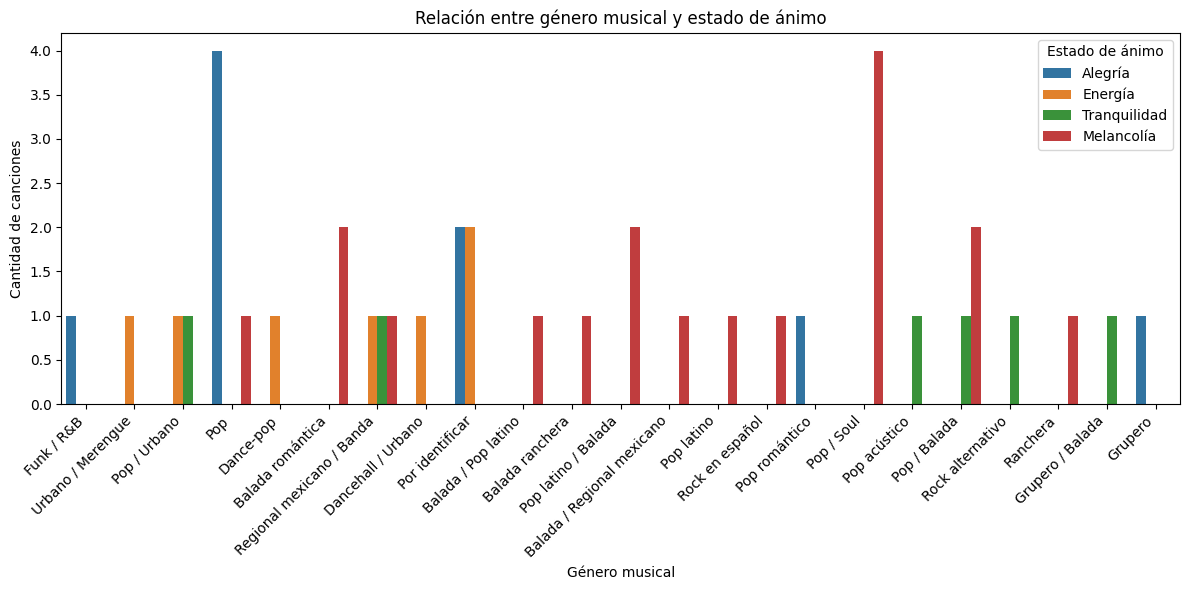

In [6]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df_limpio,
    x="genero",
    hue="estado_animo"
)

plt.title("Relación entre género musical y estado de ánimo")
plt.xlabel("Género musical")
plt.ylabel("Cantidad de canciones")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Estado de ánimo")
plt.tight_layout()
plt.show()

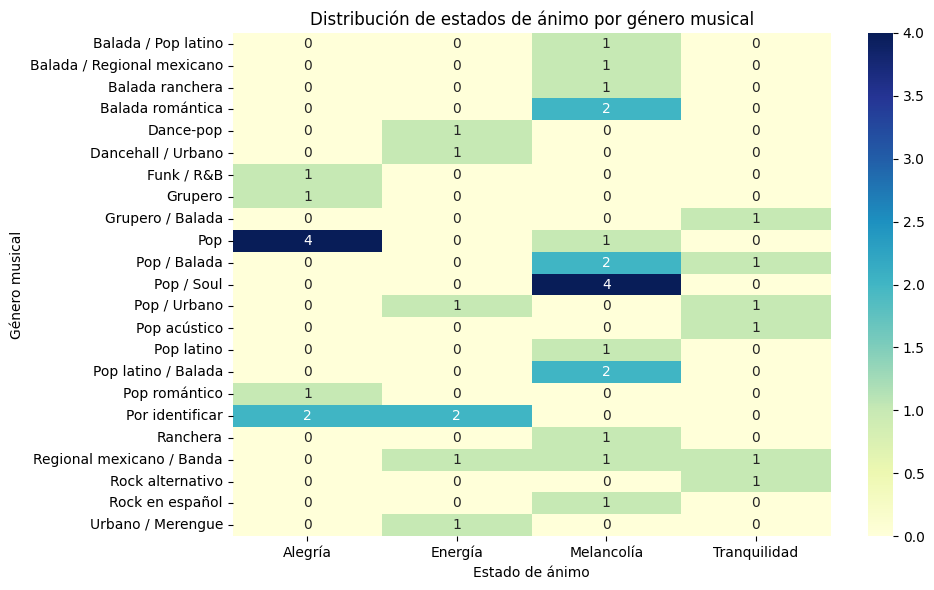

In [7]:
tabla = pd.crosstab(
    df_limpio["genero"],
    df_limpio["estado_animo"]
)

plt.figure(figsize=(10,6))

sns.heatmap(
    tabla,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Distribución de estados de ánimo por género musical")
plt.xlabel("Estado de ánimo")
plt.ylabel("Género musical")
plt.tight_layout()
plt.show()